# GHZ State — CUDA-Q Implementation

**Primitive:** 3-qubit GHZ state preparation, |GHZ> = (|000> + |111>) / sqrt(2)

**SETUP (must match the Qiskit notebook exactly for results to line up)**
- N QUBITS: 3
- GATES (shared source of truth, used for kernel build AND diagram):
  1. H on qubit 0
  2. CX, control = qubit 0, target = qubit 1
  3. CX, control = qubit 1, target = qubit 2
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** identical to the Qiskit version -- H on qubit 0 creates a
superposition, then a chain of CNOTs (CX(0,1), then CX(1,2)) propagates
that superposition to every other qubit, entangling all three into
(|000> + |111>) / sqrt(2).

**Important ordering warning:** CUDA-Q's native state-vector/sample indexing
is commonly documented as treating qubit 0 as the **most-significant**
(leftmost) bit -- opposite of Qiskit's rightmost/least-significant
convention. This notebook does NOT just assume that; Section 1 verifies it
empirically with a calibration kernel and derives `NEEDS_REVERSAL`
programmatically, and every reversal downstream is driven by that measured
flag rather than a hardcoded `[::-1]`.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError.
# Correct package name is "cudaq" (NOT "cuda-quantum").
# Requires pip >= 24.0, and Linux (x86_64/aarch64) or macOS (arm64/Apple Silicon). Windows needs WSL.
!pip install --upgrade pip -q
!pip install -q cudaq
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 18.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cudaq

np.random.seed(42)

N_QUBITS = 3
SHOTS = 10000
SEED = 42
cudaq.set_random_seed(SEED)

# GATES: shared source of truth for the matplotlib diagram, and kept in
# lockstep with the explicit kernel body below (Section 2). Format:
# (gate_name, qubits_list, param). For "h": qubits=[target].
# For "cx": qubits=[control, target].
GATES = [
    ("h",  [0],    None),
    ("cx", [0, 1], None),
    ("cx", [1, 2], None),
]
print("Gate sequence:", GATES)

Gate sequence: [('h', [0], None), ('cx', [0, 1], None), ('cx', [1, 2], None)]


## 1. Bit-ordering calibration (verify, don't assume)

We build a tiny kernel that applies X to the *highest-index* qubit only (qubit 2) and check which native statevector index lights up. Under the qubit-0-rightmost CONTRACT, the expected bitstring is `"100"` (leftmost char = qubit 2 = 1, the rest = 0). We compare CUDA-Q's actual raw output against that, and derive `NEEDS_REVERSAL` from the result instead of trusting documentation.

In [3]:
@cudaq.kernel
def _calibration_kernel():
    q = cudaq.qvector(3)
    x(q[2])  # flip the highest-index qubit only, leave the rest at |0>

calib_state = cudaq.get_state(_calibration_kernel)
calib_amps = np.array(calib_state)

nonzero_idx = int(np.argmax(np.abs(calib_amps)))
native_bitstring = format(nonzero_idx, f"0{N_QUBITS}b")
expected_contract_bitstring = "1" + "0" * (N_QUBITS - 1)  # highest qubit = leftmost = 1, rest 0

if native_bitstring == expected_contract_bitstring:
    NEEDS_REVERSAL = False
elif native_bitstring[::-1] == expected_contract_bitstring:
    NEEDS_REVERSAL = True
else:
    raise RuntimeError(f"Calibration inconclusive: got '{native_bitstring}', "
                        f"expected '{expected_contract_bitstring}' or its reverse.")

print(f"Native bitstring for X(qubit {N_QUBITS-1}) only: '{native_bitstring}'")
print(f"Expected under contract (qubit0=rightmost):        '{expected_contract_bitstring}'")
print(f"NEEDS_REVERSAL = {NEEDS_REVERSAL}")

Native bitstring for X(qubit 2) only: '100'
Expected under contract (qubit0=rightmost):        '100'
NEEDS_REVERSAL = False


## 2. Build the kernel explicitly (kept in lockstep with GATES above)

In [4]:
@cudaq.kernel
def ghz_state_kernel():
    q = cudaq.qvector(3)
    h(q[0])             # GATES[0] = ("h", [0], None)
    x.ctrl(q[0], q[1])  # GATES[1] = ("cx", [0, 1], None) -- control=q[0], target=q[1]
    x.ctrl(q[1], q[2])  # GATES[2] = ("cx", [1, 2], None) -- control=q[1], target=q[2]

# Consistency guard: if you edit the kernel body above, update GATES to match,
# or this assertion (checked against gate count in Section 7) will catch drift.
assert len(GATES) == 3, "GATES list and kernel body have drifted out of sync -- fix one or the other."


## 3. Draw/visualize the circuit

In [5]:
# Native CUDA-Q text drawing (authoritative reference)
print(cudaq.draw(ghz_state_kernel))

     ╭───╮          
q0 : ┤ h ├──●───────
     ╰───╯╭─┴─╮     
q1 : ─────┤ x ├──●──
          ╰───╯╭─┴─╮
q2 : ──────────┤ x ├
               ╰───╯



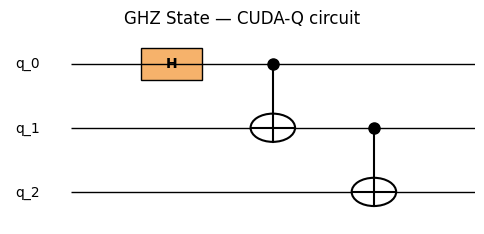

In [6]:
# Matplotlib circuit diagram, generated by looping over the shared GATES list
# above -- NOT hand-placed -- so it cannot silently drift from the kernel body.
fig, ax = plt.subplots(figsize=(6, 2.5))

for i in range(N_QUBITS):
    y = N_QUBITS - 1 - i
    ax.hlines(y, 0, len(GATES) + 1.5, color="black", linewidth=1)
    ax.text(-0.3, y, f"q_{i}", va="center", ha="right", fontsize=10)

for col, (gate_name, qubits, param) in enumerate(GATES):
    x_pos = col + 1
    if gate_name == "h":
        y = N_QUBITS - 1 - qubits[0]
        ax.add_patch(plt.Rectangle((x_pos - 0.3, y - 0.25), 0.6, 0.5,
                                    facecolor="#f6b26b", edgecolor="black"))
        ax.text(x_pos, y, "H", va="center", ha="center", fontsize=10, fontweight="bold")
    elif gate_name == "cx":
        ctrl_q, tgt_q = qubits
        y_ctrl = N_QUBITS - 1 - ctrl_q
        y_tgt = N_QUBITS - 1 - tgt_q
        ax.plot([x_pos, x_pos], [y_ctrl, y_tgt], color="black", linewidth=1.5, zorder=1)
        ax.plot(x_pos, y_ctrl, "o", color="black", markersize=8, zorder=2)
        ax.add_patch(plt.Circle((x_pos, y_tgt), 0.22, facecolor="white",
                                 edgecolor="black", linewidth=1.5, zorder=2))
        ax.plot([x_pos - 0.22, x_pos + 0.22], [y_tgt, y_tgt], color="black", linewidth=1.5, zorder=3)
        ax.plot([x_pos, x_pos], [y_tgt - 0.22, y_tgt + 0.22], color="black", linewidth=1.5, zorder=3)
    else:
        raise ValueError(f"Unhandled gate in GATES for drawing: {gate_name}")

ax.set_xlim(-0.6, len(GATES) + 1)
ax.set_ylim(-0.5, N_QUBITS - 0.5)
ax.axis("off")
ax.set_title("GHZ State — CUDA-Q circuit")

fig.savefig("ghz_state_cudaq_circuit.png", bbox_inches="tight")
fig

## 4. Explicit matrix representation of the key operator(s)

In [7]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)
print("H matrix:")
print(np.round(H_matrix, 4))
print()

def cx_matrix(control, target, n_qubits):
    """CX matrix for arbitrary control/target in an n-qubit system,
    basis ordered with qubit 0 = rightmost (LSB) -- identical construction
    to the Qiskit notebook."""
    dim = 2 ** n_qubits
    M = np.zeros((dim, dim), dtype=complex)
    for idx in range(dim):
        bits = [(idx >> k) & 1 for k in range(n_qubits)]
        if bits[control] == 1:
            bits[target] = 1 - bits[target]
        new_idx = sum(b << k for k, b in enumerate(bits))
        M[new_idx, idx] = 1
    return M

def single_qubit_op_embedded(op, qubit, n_qubits):
    """Embed a 2x2 single-qubit operator into the full n-qubit space,
    with qubit 0 = rightmost/LSB."""
    mats = []
    for q in reversed(range(n_qubits)):
        mats.append(op if q == qubit else np.eye(2, dtype=complex))
    full = mats[0]
    for m in mats[1:]:
        full = np.kron(full, m)
    return full

CX01 = cx_matrix(0, 1, N_QUBITS)
CX12 = cx_matrix(1, 2, N_QUBITS)
H_embedded = single_qubit_op_embedded(H_matrix, 0, N_QUBITS)

print(f"CX(control=0, target=1) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CX01.real, 4))
print()
print(f"CX(control=1, target=2) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CX12.real, 4))

full_op = CX12 @ CX01 @ H_embedded
print()
print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator (basis qubit0=rightmost):")
print(np.round(full_op, 4))

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

CX(control=0, target=1) matrix, 8x8, basis qubit0=rightmost:
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]]

CX(control=1, target=2) matrix, 8x8, basis qubit0=rightmost:
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]]

Full 8x8 operator (basis qubit0=rightmost):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.

## 5. Exact statevector, reordered (if needed) + global-phase normalized

In [8]:
state = cudaq.get_state(ghz_state_kernel)
raw_amps = np.array(state)
print("Raw CUDA-Q amplitudes (native ordering):")
print(np.round(raw_amps, 4))

Raw CUDA-Q amplitudes (native ordering):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]


In [9]:
def reorder_if_needed(amps, n_qubits, needs_reversal):
    if not needs_reversal:
        return amps.copy()
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for native_idx in range(dim):
        native_bits = format(native_idx, f"0{n_qubits}b")
        target_bits = native_bits[::-1]
        target_idx = int(target_bits, 2)
        reordered[target_idx] = amps[native_idx]
    return reordered

amps_contract = reorder_if_needed(raw_amps, N_QUBITS, NEEDS_REVERSAL)
print(f"Amplitudes after reordering (NEEDS_REVERSAL={NEEDS_REVERSAL}, matches CONTRACT):")
print(np.round(amps_contract, 4))

Amplitudes after reordering (NEEDS_REVERSAL=False, matches CONTRACT):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]


In [10]:
# Global phase normalization -- identical method to the Qiskit notebook.
def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps_contract, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


## 6. Measurement: sample, plot histogram

In [11]:
result = cudaq.sample(ghz_state_kernel, shots_count=SHOTS)
raw_counts = {bs: result.count(bs) for bs in result}
print("Raw CUDA-Q counts (native bitstring ordering):")
print(raw_counts)

Raw CUDA-Q counts (native bitstring ordering):
{'111': 5053, '000': 4947}


In [12]:
def reorder_counts_if_needed(counts, needs_reversal):
    if not needs_reversal:
        return dict(counts)
    out = {}
    for bs, c in counts.items():
        rbs = bs[::-1]
        out[rbs] = out.get(rbs, 0) + c
    return out

counts = reorder_counts_if_needed(raw_counts, NEEDS_REVERSAL)
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}), qubit0 = rightmost:")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42), qubit0 = rightmost:
{'000': 0.4947, '111': 0.5053}


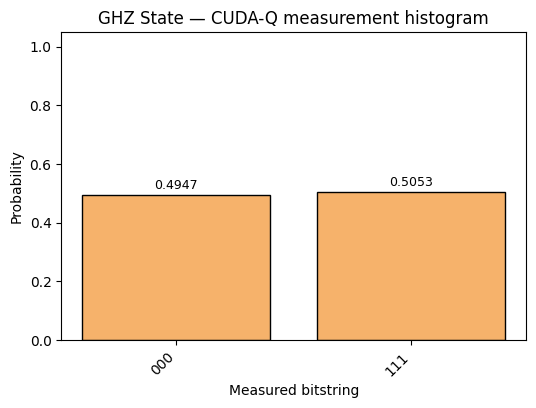

In [13]:
# Matplotlib bar chart styled like Qiskit's plot_histogram()
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = list(sampled_probs.keys())
values = list(sampled_probs.values())

ax2.bar(labels, values, color="#f6b26b", edgecolor="black")
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title("GHZ State — CUDA-Q measurement histogram")
ax2.set_ylim(0, 1.05)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, str(v), ha="center", fontsize=9)

fig2.savefig("ghz_state_cudaq_histogram.png", bbox_inches="tight")
fig2

## 7. Gate / operation count

In [14]:
gate_count = len(GATES)  # h + 2x cx
print(f"Gate/operation count: {gate_count}")

Gate/operation count: 3


## 8. Convention notes

In [15]:
print(f"Bit ordering: calibration in Section 1 measured NEEDS_REVERSAL = {NEEDS_REVERSAL}")
print("(derived from an actual X-on-qubit-2 calibration kernel, not assumed from docs).")
print("Every downstream reversal -- statevector and sampled counts -- used that measured flag.")
print()
print("Global phase: computed and removed using the identical method as the Qiskit notebook --")
print("first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.")
print("For this primitive, both nonzero amplitudes (|000>, |111>) are real and equal by")
print("construction, so this normalization step is a no-op here.")

Bit ordering: calibration in Section 1 measured NEEDS_REVERSAL = False
(derived from an actual X-on-qubit-2 calibration kernel, not assumed from docs).
Every downstream reversal -- statevector and sampled counts -- used that measured flag.

Global phase: computed and removed using the identical method as the Qiskit notebook --
first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.
For this primitive, both nonzero amplitudes (|000>, |111>) are real and equal by
construction, so this normalization step is a no-op here.


## 9. Hand-derived expected result (independent sanity check)

Derived directly from the gate definitions, independent of the code above: H puts qubit 0 into (|0>+|1>)/sqrt(2); CX(0,1) copies that value onto qubit 1, and CX(1,2) then copies qubit 1's value onto qubit 2, so all three qubits end up equal -- (|000> + |111>) / sqrt(2). Expected probabilities: `{'000': 0.5, '111': 0.5}`, all other bitstrings 0.

In [16]:
EXPECTED_PROBS = {format(i, f"0{N_QUBITS}b"): 0.0 for i in range(2 ** N_QUBITS)}
EXPECTED_PROBS["0" * N_QUBITS] = 0.5
EXPECTED_PROBS["1" * N_QUBITS] = 0.5

max_delta_vs_hand = max(abs(exact_probs.get(k, 0) - EXPECTED_PROBS.get(k, 0))
                         for k in set(exact_probs) | set(EXPECTED_PROBS))
print("Max delta vs. hand-derived expectation:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-6, "Computed result does not match hand-derived GHZ state probabilities!"
print("Sanity check PASSED: exact_probs matches the hand-derived expectation.")

Max delta vs. hand-derived expectation: 0.0
Sanity check PASSED: exact_probs matches the hand-derived expectation.


## Final result (for diffing against QISKIT_RESULT)

In [17]:
CUDAQ_RESULT = exact_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}
